# GMM

Found 4 images
Common histogram X-axis: 0.0000 – 0.4883


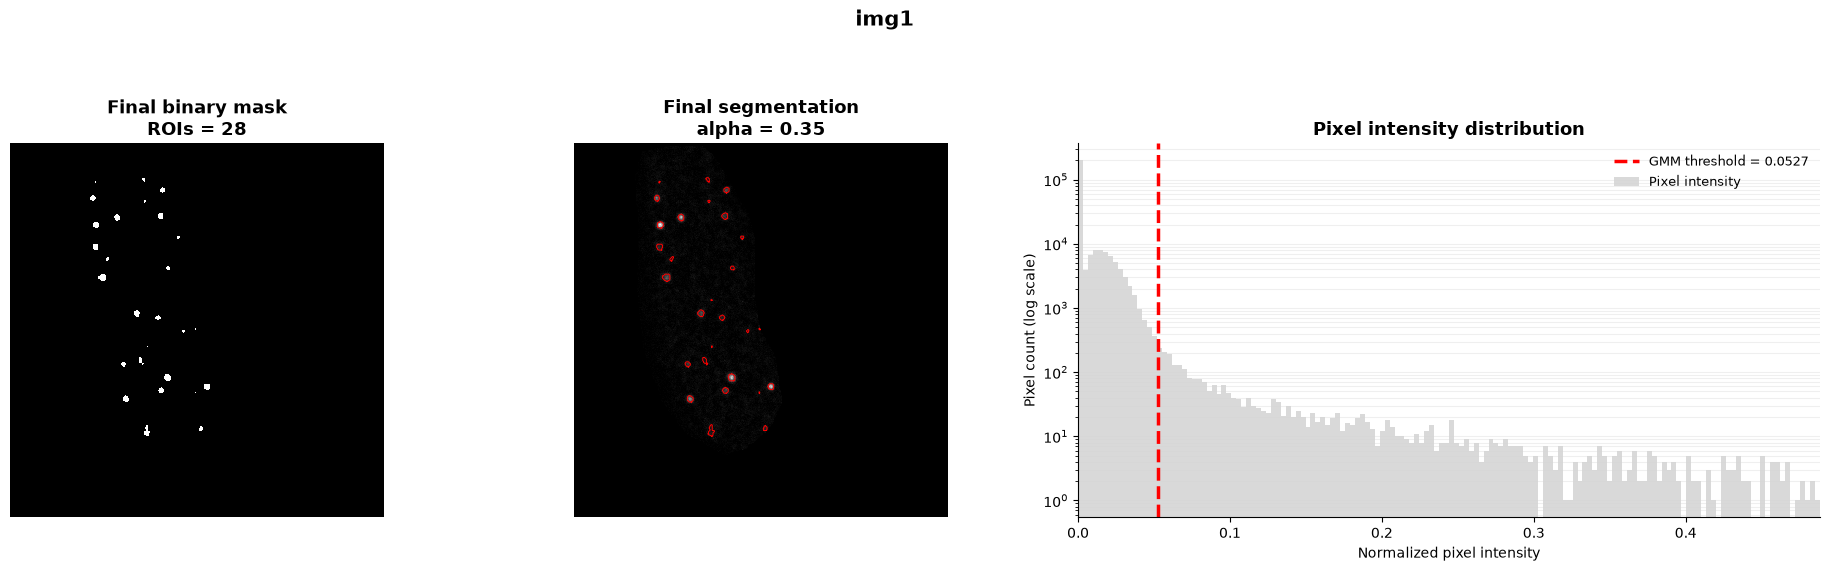

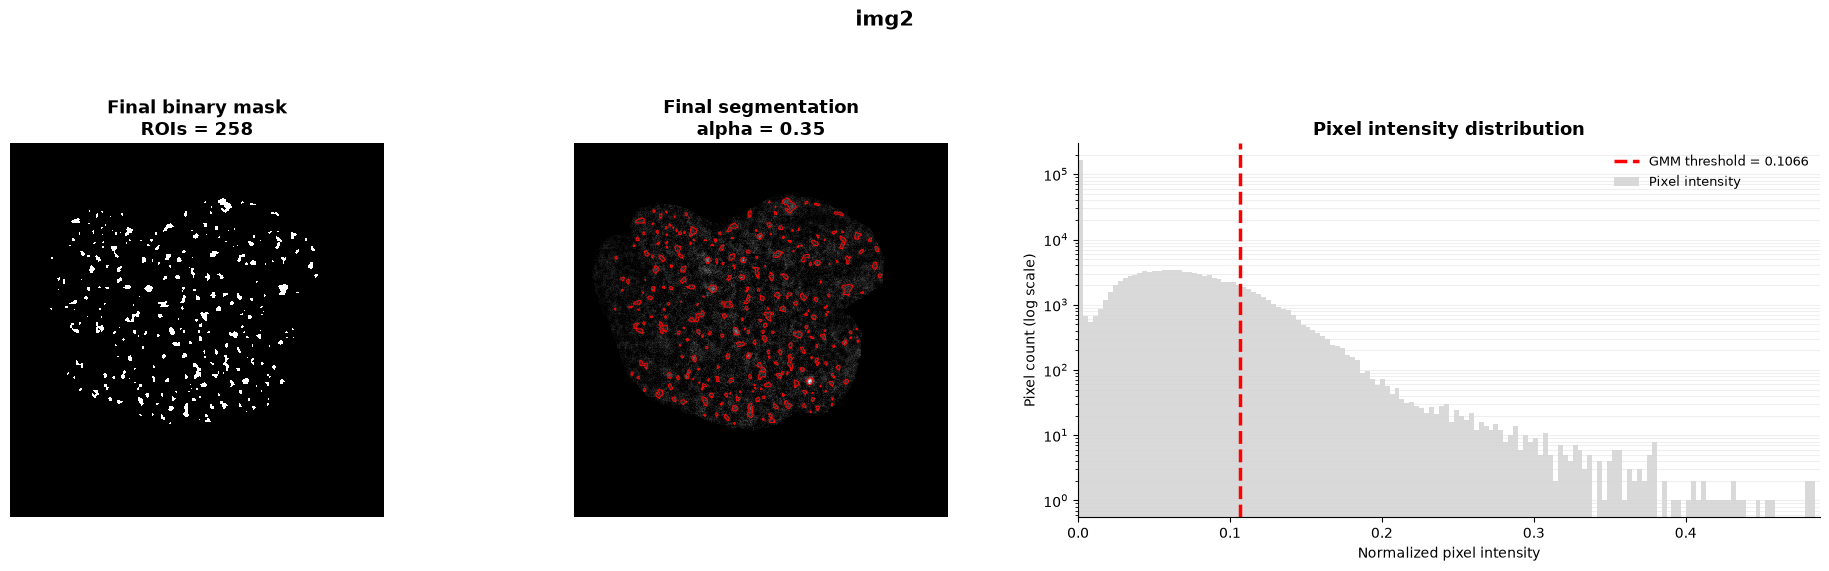

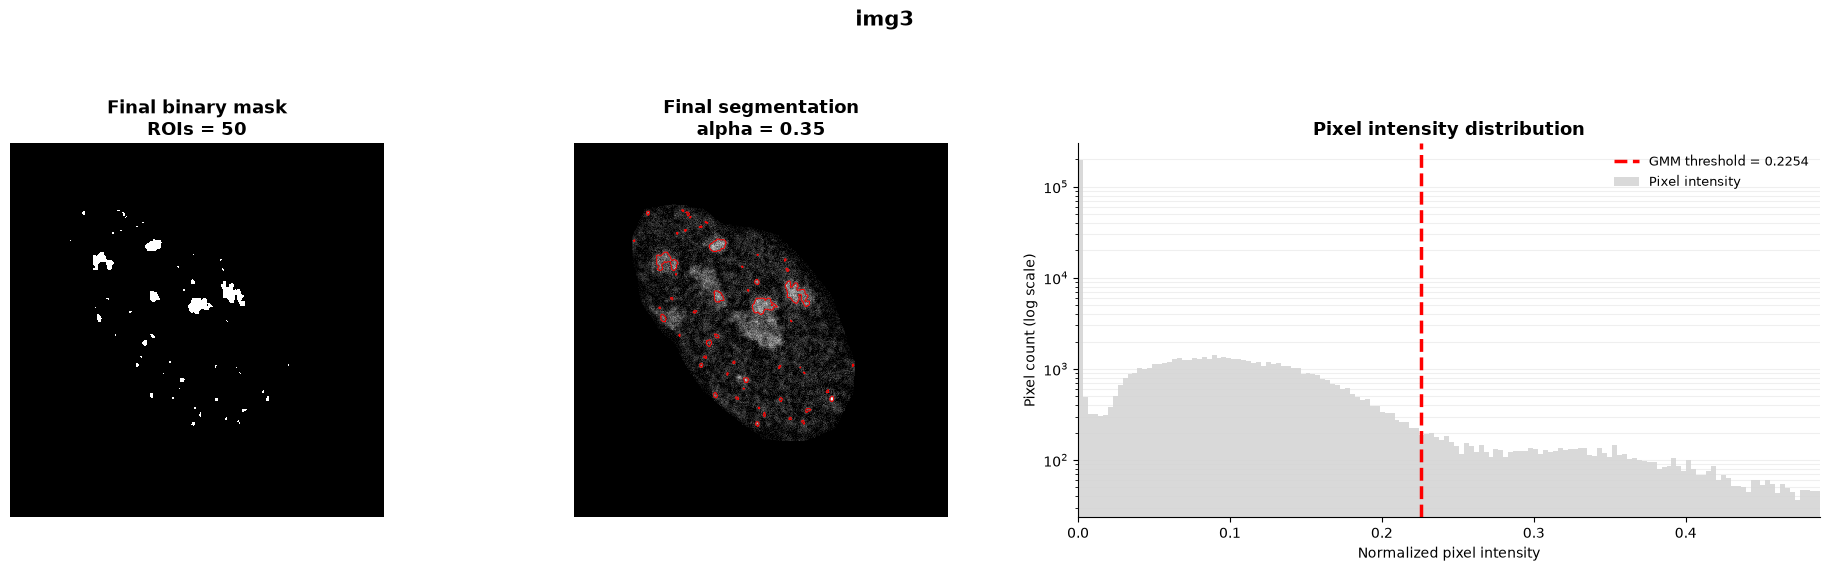

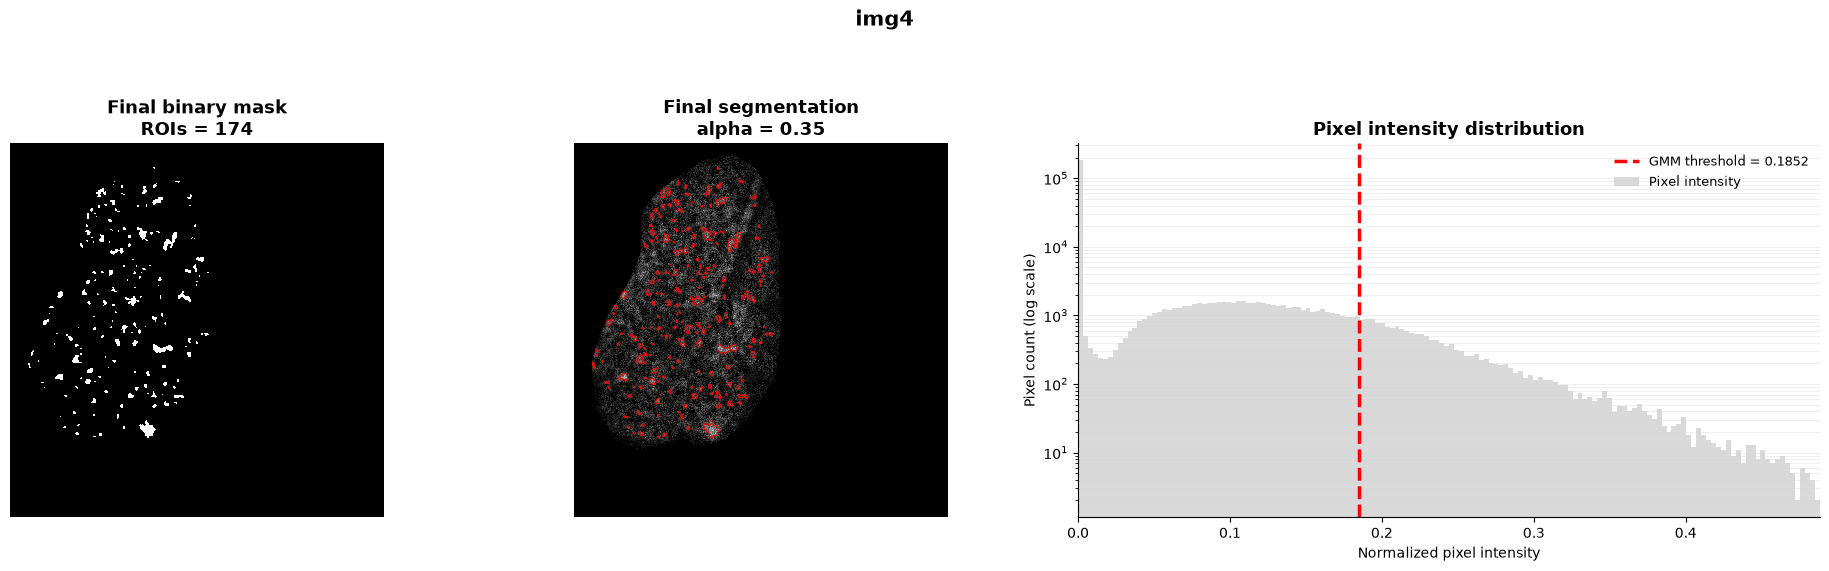


SEGMENTATION SUMMARY
image  GMM_threshold  initial_ROIs  refined_ROIs  initial_area_px  refined_area_px  alpha
 img1       0.052705            28            28             2751              984   0.35
 img2       0.106611           258           258            19358             5597   0.35
 img3       0.225423            50            50             9164             2329   0.35
 img4       0.185219           174           174            17616             3652   0.35

All results saved to:
/home/lopatushka/LLPS/Foci/GMM/GMM_refined_segmentation


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage as ndi

from sklearn.mixture import GaussianMixture
from skimage import io, filters, morphology, measure
from skimage.color import rgb2gray


# =====================================================
# 1. PARAMETERS AND FOLDERS
# =====================================================

input_dir = Path("images")
output_dir = Path("GMM_refined_segmentation")

figures_dir = output_dir / "figures"
masks_dir = output_dir / "masks"
labels_dir = output_dir / "labels"
measurements_dir = output_dir / "measurements"

for folder in [
    output_dir,
    figures_dir,
    masks_dir,
    labels_dir,
    measurements_dir
]:
    folder.mkdir(parents=True, exist_ok=True)

# Load all TIFF files
image_paths = sorted([
    p for p in input_dir.iterdir()
    if p.is_file() and p.suffix.lower() in (".tif", ".tiff")
]) if input_dir.exists() else []

if not image_paths:
    raise FileNotFoundError(
        f"No TIFF images found in {input_dir.resolve()}"
    )

print(f"Found {len(image_paths)} images")


# Segmentation parameters
sigma = 1.2

n_components = 3
random_state = 42
n_init = 10
max_iter = 300
max_fit_pixels = None

min_area = 3
connectivity = 2

alpha = 0.35
background_percentile = 10
refined_min_area = 1

hist_bins = 150


# =====================================================
# 2. LOAD IMAGE
# =====================================================

def load_image(image_path):

    image = io.imread(image_path)

    if image.ndim == 3 and image.shape[-1] in (3, 4):
        image = rgb2gray(image[..., :3])

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image, got {image.shape}"
        )

    image = image.astype(np.float64)

    if not np.isfinite(image).all():
        raise ValueError("Image contains NaN or Inf")

    imin = image.min()
    imax = image.max()

    if imax <= imin:
        raise ValueError("Image has constant intensity")

    return (image - imin) / (imax - imin)


# =====================================================
# 3. FIT GMM
# =====================================================

def fit_gmm(image):

    pixels = image.reshape(-1, 1)

    if (
        max_fit_pixels is not None
        and len(pixels) > max_fit_pixels
    ):
        rng = np.random.default_rng(random_state)

        indices = rng.choice(
            len(pixels),
            size=max_fit_pixels,
            replace=False
        )

        fit_pixels = pixels[indices]

    else:
        fit_pixels = pixels

    gmm = GaussianMixture(
        n_components=n_components,
        covariance_type="full",
        random_state=random_state,
        n_init=n_init,
        max_iter=max_iter,
        reg_covar=1e-6
    )

    gmm.fit(fit_pixels)

    return gmm


# =====================================================
# 4. GMM PARAMETERS AND THRESHOLD
# =====================================================

def get_gmm_parameters(gmm):

    means = gmm.means_.flatten()
    stds = np.sqrt(gmm.covariances_.reshape(-1))
    weights = gmm.weights_

    order = np.argsort(means)

    return (
        means[order],
        stds[order],
        weights[order]
    )


def find_gmm_threshold(gmm, means, grid_size=10000):

    intensity_grid = np.linspace(0, 1, grid_size)

    probabilities = gmm.predict_proba(
        intensity_grid.reshape(-1, 1)
    )

    brightest_component = np.argmax(
        gmm.means_.flatten()
    )

    predicted_components = np.argmax(
        probabilities,
        axis=1
    )

    candidates = np.where(
        (intensity_grid >= means[-2])
        & (predicted_components == brightest_component)
    )[0]

    if len(candidates) == 0:
        raise ValueError(
            "No high-intensity GMM decision region found"
        )

    return intensity_grid[candidates[0]]


# =====================================================
# 5. INITIAL SEGMENTATION
# =====================================================

def segment_image(smooth, threshold):

    mask = smooth > threshold

    mask = ndi.binary_fill_holes(mask)

    mask = morphology.remove_small_objects(
        mask,
        min_size=min_area,
        connectivity=connectivity
    )

    labels = measure.label(
        mask,
        connectivity=connectivity
    )

    return mask, labels


# =====================================================
# 6. LOCAL ROI REFINEMENT
# =====================================================

def refine_gmm_rois(
    smooth,
    labels,
    alpha=0.35,
    min_area=1,
    background_percentile=10
):

    refined_labels = np.zeros(
        labels.shape,
        dtype=np.int32
    )

    next_label = 1

    for region in measure.regionprops(labels):

        minr, minc, maxr, maxc = region.bbox

        local_image = smooth[
            minr:maxr,
            minc:maxc
        ]

        local_roi = (
            labels[minr:maxr, minc:maxc]
            == region.label
        )

        intensities = local_image[local_roi]

        background = np.percentile(
            intensities,
            background_percentile
        )

        peak = intensities.max()

        local_threshold = (
            background
            + alpha * (peak - background)
        )

        refined = (
            local_roi
            & (local_image >= local_threshold)
        )

        components = measure.label(
            refined,
            connectivity=connectivity
        )

        peak_position = np.unravel_index(
            np.argmax(
                np.where(
                    local_roi,
                    local_image,
                    -np.inf
                )
            ),
            local_image.shape
        )

        peak_label = components[peak_position]

        if peak_label == 0:
            continue

        refined = components == peak_label

        if np.count_nonzero(refined) < min_area:
            continue

        local_output = refined_labels[
            minr:maxr,
            minc:maxc
        ]

        local_output[refined] = next_label

        next_label += 1

    refined_mask = refined_labels > 0

    return refined_mask, refined_labels


# =====================================================
# 7. DRAW CONTOURS
# =====================================================

def draw_contours(ax, image, labels):

    ax.imshow(
        image,
        cmap="gray",
        interpolation="nearest"
    )

    for region in measure.regionprops(labels):

        roi_mask = labels == region.label

        contours = measure.find_contours(
            np.pad(
                roi_mask.astype(float),
                1,
                mode="constant"
            ),
            level=0.5
        )

        for contour in contours:

            ax.plot(
                contour[:, 1] - 1,
                contour[:, 0] - 1,
                color="red",
                linewidth=0.7
            )

    ax.axis("off")


# =====================================================
# 8. LOAD IMAGES AND FIT GMM FROM SCRATCH
# =====================================================

prepared = []

for image_path in image_paths:

    image = load_image(image_path)

    smooth = filters.gaussian(
        image,
        sigma=sigma
    )

    gmm = fit_gmm(smooth)

    means, stds, weights = get_gmm_parameters(gmm)

    threshold = find_gmm_threshold(
        gmm,
        means
    )

    prepared.append({
        "path": image_path,
        "image": image,
        "smooth": smooth,
        "means": means,
        "stds": stds,
        "weights": weights,
        "threshold": threshold
    })


# =====================================================
# 9. COMMON HISTOGRAM X-AXIS
# =====================================================

all_pixels = np.concatenate([
    item["smooth"].ravel()
    for item in prepared
])

all_thresholds = [
    item["threshold"]
    for item in prepared
]

hist_low = max(
    0.0,
    min(
        np.percentile(all_pixels, 0.1),
        min(all_thresholds)
    )
)

hist_high = min(
    1.0,
    max(
        np.percentile(all_pixels, 99.9),
        max(all_thresholds) * 1.15
    )
)

if hist_high <= hist_low:
    hist_low, hist_high = 0.0, 1.0

print(
    f"Common histogram X-axis: "
    f"{hist_low:.4f} – {hist_high:.4f}"
)


# =====================================================
# 10. SEGMENT, PLOT AND SAVE
# =====================================================

results = {}
summary = []
all_measurements = []

for item in prepared:

    image_path = item["path"]
    image_name = image_path.stem

    image = item["image"]
    smooth = item["smooth"]

    means = item["means"]
    stds = item["stds"]
    weights = item["weights"]

    T_gmm = item["threshold"]

    initial_mask, initial_labels = segment_image(
        smooth,
        T_gmm
    )

    refined_mask, refined_labels = refine_gmm_rois(
        smooth,
        initial_labels,
        alpha=alpha,
        min_area=refined_min_area,
        background_percentile=background_percentile
    )

    n_initial = int(initial_labels.max())
    n_refined = int(refined_labels.max())

    # ----------------------------------------------
    # FIGURE
    # ----------------------------------------------

    fig, axes = plt.subplots(
        1, 3,
        figsize=(19, 5.5),
        gridspec_kw={
            "width_ratios": [1, 1, 1.5]
        }
    )

    # PANEL 1: FINAL BINARY MASK

    axes[0].imshow(
        refined_mask,
        cmap="gray",
        interpolation="nearest"
    )

    axes[0].set_title(
        f"Final binary mask\nROIs = {n_refined}",
        fontsize=13,
        fontweight="bold"
    )

    axes[0].axis("off")

    # PANEL 2: FINAL SEGMENTATION

    draw_contours(
        axes[1],
        image,
        refined_labels
    )

    axes[1].set_title(
        f"Final segmentation\nalpha = {alpha}",
        fontsize=13,
        fontweight="bold"
    )

    # PANEL 3: HISTOGRAM + GMM THRESHOLD

    ax = axes[2]

    pixels = smooth.ravel()

    counts, edges = np.histogram(
        pixels,
        bins=hist_bins,
        range=(hist_low, hist_high)
    )

    centers = (edges[:-1] + edges[1:]) / 2
    bin_widths = np.diff(edges)

    ax.bar(
        centers,
        counts,
        width=bin_widths,
        color="lightgray",
        alpha=0.85,
        edgecolor="none",
        label="Pixel intensity"
    )

    ax.axvline(
        T_gmm,
        color="red",
        linestyle="--",
        linewidth=2.5,
        label=f"GMM threshold = {T_gmm:.4f}"
    )

    ax.set_yscale("log")
    ax.set_xlim(hist_low, hist_high)

    ax.set_xlabel("Normalized pixel intensity")
    ax.set_ylabel("Pixel count (log scale)")

    ax.set_title(
        "Pixel intensity distribution",
        fontsize=13,
        fontweight="bold"
    )

    ax.grid(
        axis="y",
        which="both",
        alpha=0.2
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        fontsize=9,
        frameon=False
    )

    # ----------------------------------------------
    # FIGURE SETTINGS
    # ----------------------------------------------

    fig.suptitle(
        image_name,
        fontsize=15,
        fontweight="bold",
        y=1.03
    )

    fig.tight_layout(
        rect=[0, 0, 1, 0.92]
    )

    fig.savefig(
        figures_dir / f"{image_name}_GMM_refined.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # ----------------------------------------------
    # SAVE MASKS AND LABELS
    # ----------------------------------------------

    io.imsave(
        masks_dir / f"{image_name}_refined_mask.tif",
        (refined_mask * 255).astype(np.uint8),
        check_contrast=False
    )

    io.imsave(
        labels_dir / f"{image_name}_refined_labels.tif",
        refined_labels.astype(np.int32),
        check_contrast=False
    )

    # ----------------------------------------------
    # ROI MEASUREMENTS
    # ----------------------------------------------

    properties = measure.regionprops_table(
        refined_labels,
        intensity_image=image,
        properties=[
            "label",
            "area",
            "centroid",
            "equivalent_diameter_area",
            "perimeter",
            "solidity",
            "mean_intensity",
            "max_intensity"
        ]
    )

    roi_df = pd.DataFrame(properties)
    roi_df.insert(0, "image", image_name)

    roi_df.to_csv(
        measurements_dir / f"{image_name}_ROIs.csv",
        index=False
    )

    all_measurements.append(roi_df)

    # ----------------------------------------------
    # SUMMARY
    # ----------------------------------------------

    summary.append({
        "image": image_name,
        "GMM_threshold": T_gmm,
        "initial_ROIs": n_initial,
        "refined_ROIs": n_refined,
        "initial_area_px": int(initial_mask.sum()),
        "refined_area_px": int(refined_mask.sum()),
        "alpha": alpha
    })

    results[image_name] = {
        "threshold": T_gmm,
        "means": means,
        "stds": stds,
        "weights": weights,
        "initial_mask": initial_mask,
        "initial_labels": initial_labels,
        "refined_mask": refined_mask,
        "refined_labels": refined_labels,
        "roi_df": roi_df
    }


# =====================================================
# 11. SAVE COMBINED RESULTS
# =====================================================

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    output_dir / "GMM_summary.csv",
    index=False
)

all_rois_df = pd.concat(
    all_measurements,
    ignore_index=True
)

all_rois_df.to_csv(
    output_dir / "GMM_all_ROIs.csv",
    index=False
)

print("\nSEGMENTATION SUMMARY")
print(summary_df.to_string(index=False))

print("\nAll results saved to:")
print(output_dir.resolve())
